In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

# Load all three files 

# customer-level RFM + churn label
rfm  = pd.read_csv("../data/processed/rfm_features.csv")

 # scaled version for clustering
rfm_scaled = pd.read_csv("../data/processed/rfm_scaled.csv")

# transaction-level with log features
tx = pd.read_csv("../data/processed/transaction_features.csv")

print("RFM shape:", rfm.shape)
print ("RFM scaled shape:", rfm_scaled.shape)
print ("Transaction shape:", tx.shape)

RFM shape: (5878, 7)
RFM scaled shape: (5878, 6)
Transaction shape: (779425, 12)


In [2]:
# Select only the 5 scaled features for clustering - Customer ID excluded
# Use scaled features for clustering

X =  rfm_scaled[['Recency','Frequency','Monetary','AvgOrderValue','TotalItems']]

print("Clustering data shape:", X.shape)

Clustering data shape: (5878, 5)


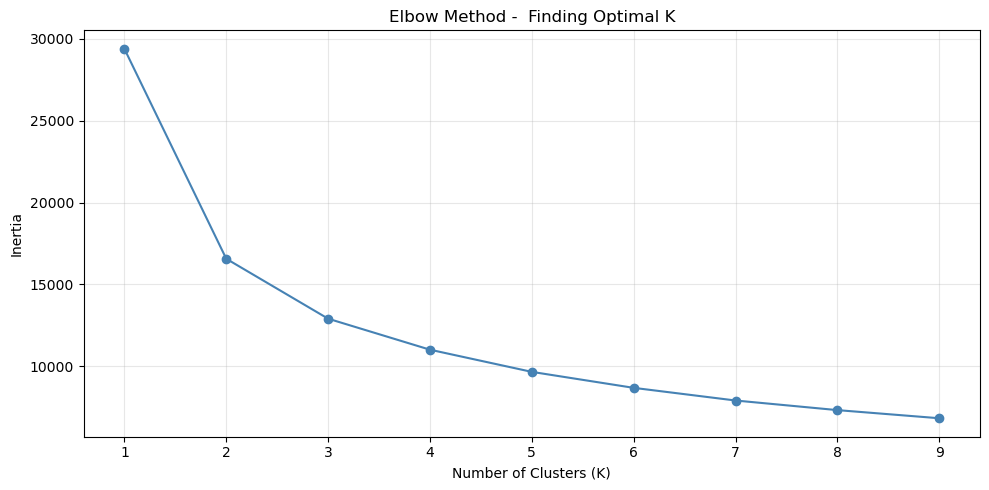

In [3]:


from sklearn.cluster import KMeans

 # stores how compact each clustering is - lower = tighter clusters
inertia = []

# Try K from 1 to 9 and record inertia for each
for k in range(1, 10):
    model =  KMeans(n_clusters=k, random_state=42, n_init=10)# n_init=10 runs 10 times to avoid bad starts
    model.fit(X)

    # inertia = sum of squared distances to nearest cluster centre
    inertia.append(model.inertia_)

# Plot inertia vs K - the "elbow" point suggests the optimal number of clusters
plt.figure(figsize=(10, 5))
plt.plot(range(1, 10), inertia, marker='o', color='steelblue')
plt.title("Elbow Method -  Finding Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:

# K is selected from data

from sklearn.metrics import silhouette_score

 # stores silhouette score for each K
scores   = []

# test K from 2 to 7 
k_values = list(range(2, 8))

print("Silhouette Scores:\n")

for k in k_values:
    model  = KMeans(n_clusters=k, random_state=42, n_init=10)

    # fit model and return cluster label for each customer
    labels = model.fit_predict(X)

    # score closer to 1 = well separated clusters
    score  = silhouette_score(X, labels)

    scores.append(score)
    print(f"  K={k}: {round(score, 4)}")

# Pick K with the highest silhouette score
best_k = k_values[scores.index(max(scores))]

print(f"\nSelected K: {best_k}")

print (f"Reason: Highest silhouette score of {round(max(scores), 4)}")

Silhouette Scores:

  K=2: 0.3734
  K=3: 0.284
  K=4: 0.2643
  K=5: 0.258
  K=6: 0.2484
  K=7: 0.2471

Selected K: 2
Reason: Highest silhouette score of 0.3734


In [5]:
# Train final KMeans model using the best K found above
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)

# Fit model and assign a cluster label (0 to K-1) to every customer
rfm['Cluster'] = kmeans.fit_predict(X)

print ("Customers per cluster:")

# show how many customers in each cluster
print(rfm['Cluster'].value_counts().sort_index())

Customers per cluster:
Cluster
0    3378
1    2500
Name: count, dtype: int64


In [6]:

profile_cols    = ['Recency','Frequency','Monetary','AvgOrderValue','TotalItems']

# Calculate the mean of each RFM feature per cluster - shows what each segment looks like
cluster_summary = rfm.groupby('Cluster')[profile_cols].mean().round(2)

print(" CLUSTER PROFILES \n")
display(cluster_summary)

 CLUSTER PROFILES 



,Recency,Frequency,Monetary,AvgOrderValue,TotalItems
Cluster,,,,,
0,294.25,2.08,492.96,265.05,272.30
1,73.42,11.97,6283.84,547.50,3837.65


In [7]:
# For each cluster, calculate what percentage of customers are churned

for cluster in sorted(rfm['Cluster'].unique()):

   
    subset     = rfm[rfm['Cluster'] == cluster] # filter to this cluster only
    churn_rate = round(subset['Churn'].mean() * 100, 1) # mean of 0/1 = proportion churned

    print (f"Cluster {cluster}: {len(subset):,} customers | Churn rate: {churn_rate}%")

Cluster 0: 3,378 customers | Churn rate: 72.4%
Cluster 1: 2,500 customers | Churn rate: 21.8%


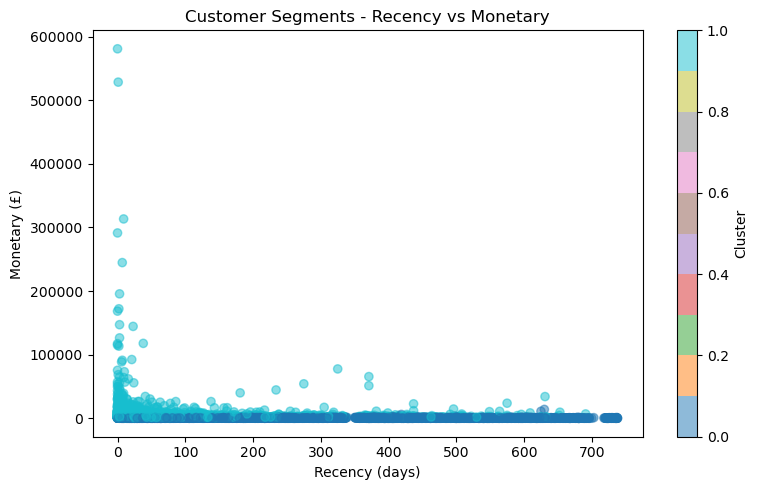

In [8]:
# Scatter plot using raw Recency and Monetary values - easier to interpret than scaled values
# Colour each point by its cluster label

plt.figure(figsize=(8, 5))
plt.scatter(rfm['Recency'], rfm['Monetary'],
            c=rfm['Cluster'], cmap='tab10', alpha=0.5)
plt.xlabel("Recency (days)")

plt.ylabel("Monetary (£)")
plt.title("Customer Segments - Recency vs Monetary")

plt.colorbar(label='Cluster') # add colour legend showing which colour = which cluster
plt.tight_layout()
plt.show()

In [9]:


from sklearn.model_selection import train_test_split

# Recency is excluded - churn was defined as Recency >= 90 days
# Including it would let the model cheat (data leakage)

X_churn =  rfm[['Frequency','Monetary','AvgOrderValue','TotalItems']]
y_churn = rfm['Churn']  # target: 1 = churned, 0 = active


# Split into 80% train and 20% test
# stratify ensures same churn ratio in both train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_churn, y_churn, test_size=0.2, random_state=42, stratify=y_churn
)

print("Train size:", len(X_train))
print("Test size: ", len(X_test))
print ("Churn in test:", y_test.sum())    # how many churned in test set
print ("Active in test:", (1 - y_test).sum()) # how many active in test set

Train size: 4702
Test size:  1176
Churn in test: 598
Active in test: 578


In [10]:


from sklearn.linear_model import LogisticRegression
from sklearn.tree         import DecisionTreeClassifier
from sklearn.ensemble     import RandomForestClassifier



models = { "Logistic Regression": LogisticRegression(max_iter=1000),
           "Decision Tree": DecisionTreeClassifier(), 
           "Random Forest":   RandomForestClassifier()
           }

# will store accuracy and F1 score for each model
results = {}

In [11]:


from sklearn.metrics import accuracy_score, f1_score

for name, model in models.items():

    model.fit(X_train, y_train) # train on training data 
    y_pred = model.predict(X_test) # predict on unseen test data

    acc =  accuracy_score(y_test, y_pred)  # proportion of correct predictions
    f1  =   f1_score(y_test, y_pred)  # balances precision and recall - better for imbalanced classes

# store both scores for comparison
    results[name] = (acc, f1)

    print (f"{name}")
    print (f"  Accuracy: {round(acc, 4)}")
    print(f"  F1 Score: {round(f1, 4)}\n")



Logistic Regression
  Accuracy: 0.7083
  F1 Score: 0.7411

Decision Tree
  Accuracy: 0.6156
  F1 Score: 0.6163

Random Forest
  Accuracy: 0.6573
  F1 Score: 0.6588



In [12]:
# selecting best model 

# Convert results dict to a dataframe for easy comparison
results_df = pd.DataFrame(results, index=['Accuracy','F1']).T

# rank by F1 score
results_df = results_df.sort_values(by='F1', ascending=False)

display(results_df)

# Pick the model with the highest F1 score automatically
best_model_name =  results_df['F1'].idxmax()
best_model = models[best_model_name]

print(f"Selected model: {best_model_name}")
print("Reason: Highest F1 score")

,Accuracy,F1
Logistic Regression,0.708333,0.741132
Random Forest,0.657313,0.658764
Decision Tree,0.615646,0.616299


Selected model: Logistic Regression
Reason: Highest F1 score


In [13]:
# DETAILED EVALUATION


from sklearn.metrics import confusion_matrix, classification_report

# Use the best model to predict on the test set
y_pred = best_model.predict(X_test)

print(f"Best Model: {best_model_name}\n")

# Confusion matrix shows true positives, false positives, true negatives, false negatives
print ("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Classification report shows precision, recall and F1 per class
print("\nClassification Report:")
print  (classification_report(y_test, y_pred))

Best Model: Logistic Regression

Confusion Matrix:
[[342 236]
 [107 491]]

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.59      0.67       578
           1       0.68      0.82      0.74       598

    accuracy                           0.71      1176
   macro avg       0.72      0.71      0.70      1176
weighted avg       0.72      0.71      0.70      1176



ROC AUC: 0.7776


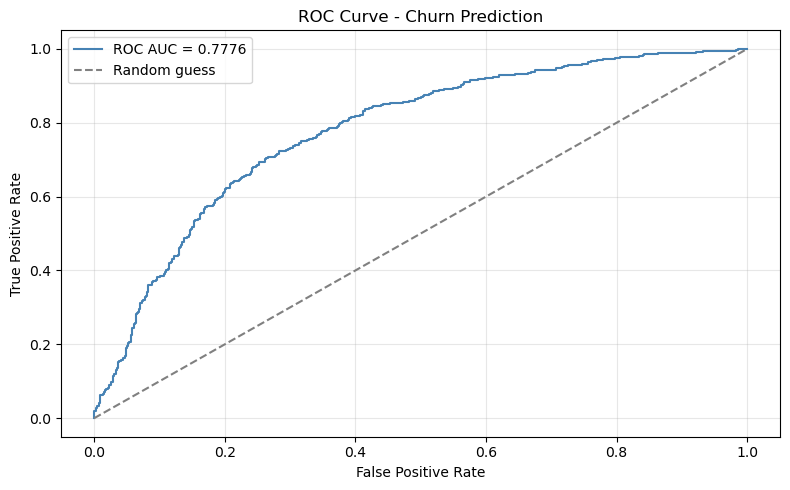

In [14]:
# ROC AUC score and curve
from sklearn.metrics import roc_auc_score, roc_curve


# predict_proba returns probability of each class - take column 1 (probability of churn)
y_proba = best_model.predict_proba(X_test)[:, 1]

# AUC measures how well the model separates churned vs active - 1.0 is perfect, 0.5 is random
auc     = round(roc_auc_score(y_test, y_proba), 4)

print(f"ROC AUC: {auc}")


# fpr = false positive rate, tpr = true positive rate at each threshold
fpr, tpr, _ = roc_curve(y_test, y_proba)

plt.figure(figsize=(8, 5))

plt.plot(fpr, tpr, color='steelblue', label=f'ROC AUC = {auc}')

plt.plot([0, 1], [0, 1], color='grey', linestyle='--', label='Random guess') # baseline
plt.title("ROC Curve - Churn Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel ("True Positive Rate")
plt.legend ()
plt.grid (True, alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# ANOMALY DETECTION


from sklearn.ensemble import IsolationForest

# Use log-transformed transaction features from notebook 06 - already on similar scales
X_anomaly = tx[['LogRevenue','LogQuantity','LogPrice']]

print("Anomaly data shape:", X_anomaly.shape)

# top 1% treated as anomalies
print("Contamination level: 0.01 (derived from notebook 6)")

Anomaly data shape: (779425, 3)
Contamination level: 0.01 (derived from notebook 6)


In [16]:
# ISOLATION FOREST


# Train Isolation Forest — contamination tells it what proportion of data to flag as anomalies
iso = IsolationForest(contamination=0.01, random_state=42)
iso_labels =  iso.fit_predict(X_anomaly)

# Count how many transactions were flagged as anomalies
iso_count  = (iso_labels == -1).sum()

print(f"Isolation Forest anomalies: {iso_count:,}")
print()
print("Selected model: Isolation Forest")
print("Reason: Scales well to large datasets and supports contamination level")


Isolation Forest anomalies: 7,785

Selected model: Isolation Forest
Reason: Scales well to large datasets and supports contamination level


In [17]:
# Compare anomaly transactions vs normal transactions

# Split transactions into anomalies and normal using the labels from Isolation Forest
anomalies = tx[iso_labels == -1]
normal = tx[iso_labels == 1]

# Compare average revenue and quantity - anomalies should have significantly higher values
print (f"Avg anomaly revenue:  £{round(anomalies['Revenue'].mean(), 2)}")
print(f"Avg normal revenue:   £{round(normal['Revenue'].mean(), 2)}")

print   (f"Avg anomaly quantity: {round(anomalies['Quantity'].mean(), 2)}")
print (f"Avg normal quantity:  {round(normal['Quantity'].mean(), 2)}")

Avg anomaly revenue:  £448.66
Avg normal revenue:   £17.99
Avg anomaly quantity: 329.64
Avg normal quantity:  10.3


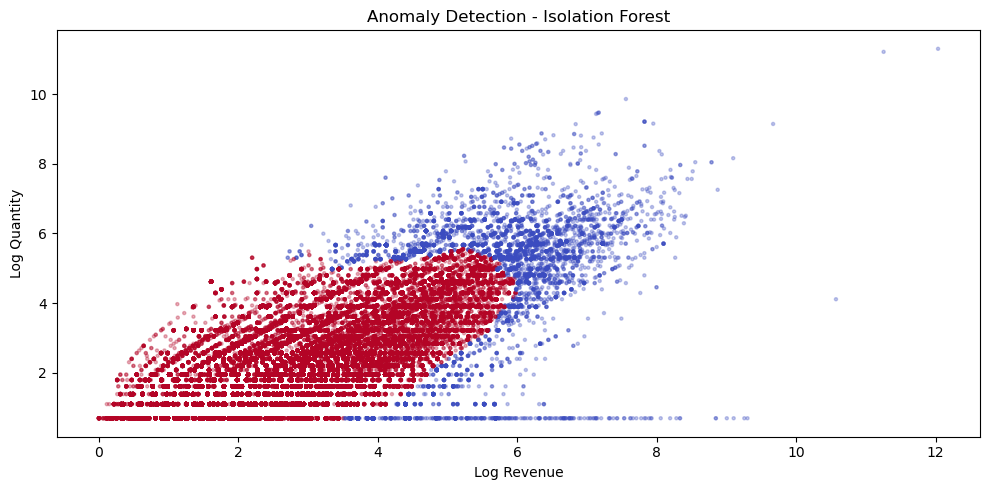

In [18]:

# ANOMALY VISUALISATION

# Scatter plot of all transactions - red = anomaly, blue = normal 

plt.figure(figsize=(10, 5))
plt.scatter(tx['LogRevenue'], tx['LogQuantity'],
            c=iso_labels, cmap='coolwarm', alpha=0.3, s=5)
plt.xlabel("Log Revenue")
plt.ylabel("Log Quantity")

plt.title("Anomaly Detection - Isolation Forest")
plt.tight_layout()
plt.show()

In [19]:
# SAVE MODELS

import joblib

joblib.dump(kmeans,     "../models/kmeans_model.pkl") # customer segmentation model
joblib.dump(best_model, "../models/churn_model.pkl")  # churn prediction model
joblib.dump(iso,        "../models/anomaly_model.pkl") # anomaly detection model

print("Models saved:")
print("  kmeans_model.pkl")
print("  churn_model.pkl")
print("  anomaly_model.pkl")

Models saved:
  kmeans_model.pkl
  churn_model.pkl
  anomaly_model.pkl
